### Net Present Value
Continuing the bakery saga, the owner is now considering whether to invest in a second oven.

The investment involves:<br>
- Cost: $\$$60,000 <br>
- Useful life: 5 years <br>
- Projected value: +$\$$44,000 <br>

In [1]:
library(ggplot2)

However, every input is an estimate: <br> 
- Additional cakes sold per day: probably 40 <br>
- Profit per cake: probably $\$$4 <br>
- Annual running costs: probably $\$$22,000

To account for the uncertainty, the owner was asked to provide worst-case, most likely, and best-case estimates for each input.

In [2]:
# Inputs
oven_cost <- 60000                
years <- 5                    
discount_rate <- 0.08                  
open_days <- 300                  

# Uncertain inputs: c(lowest,most likely,highest)
extra_cakes <- c(15,40,55)         
margin <- c(3.0,4.0,4.5)     
running_cost <- c(18000,22000,28000)

currency <- "$"
set.seed(2026)

In [3]:
# Draw from a triangular distribution
rtri <- function(n, abc) {
  a <- abc[1] 
  c <- abc[2] 
  b <- abc[3]
  u <- runif(n)
  cut <- (c-a)/(b-a)
  ifelse(u < cut,
         a+sqrt(u*(b-a)*(c-a)),
         b-sqrt((1-u)*(b-a)*(b-c)))
}

annuity <- sum(1/(1+discount_rate)^(1:years))   # value today of $1 a year

npv <- function(cakes,marg,running) {
  yearly_cash <- cakes*marg*open_days-running
  yearly_cash*annuity-oven_cost
}

plan_npv <- npv(extra_cakes[2],margin[2],running_cost[2])

In [4]:
# Simulation
n_sims <- 50000

sim <- npv(rtri(n_sims,extra_cakes),rtri(n_sims,margin),rtri(n_sims,running_cost))

avg_npv <- mean(sim)
p_loss <- mean(sim < 0)
p_beat <- mean(sim >= plan_npv)
range90 <- quantile(sim, c(0.05,0.95))

fmt <- function(x) paste0(ifelse(round(x/1000) == 0, "", ifelse(x < 0,"-","+")),currency,
                          formatC(abs(x)/1000,format = "f",digits = 0),"k")

cat(sprintf("Spreadsheet NPV (most likely values): %s\n", fmt(plan_npv)))
cat(sprintf("Simulated average NPV:                %s\n", fmt(avg_npv)))
cat(sprintf("Chance of losing money (NPV < 0):     %.0f%%\n", 100 * p_loss))
cat(sprintf("Chance of doing as well as the plan:  %.0f%%\n", 100 * p_beat))
cat(sprintf("Middle 90%% of outcomes:               %s to %s\n",
            fmt(range90[1]), fmt(range90[2])))

Spreadsheet NPV (most likely values): +$44k
Simulated average NPV:                +$18k
Chance of losing money (NPV < 0):     33%
Chance of doing as well as the plan:  28%
Middle 90% of outcomes:               -$52k to +$84k


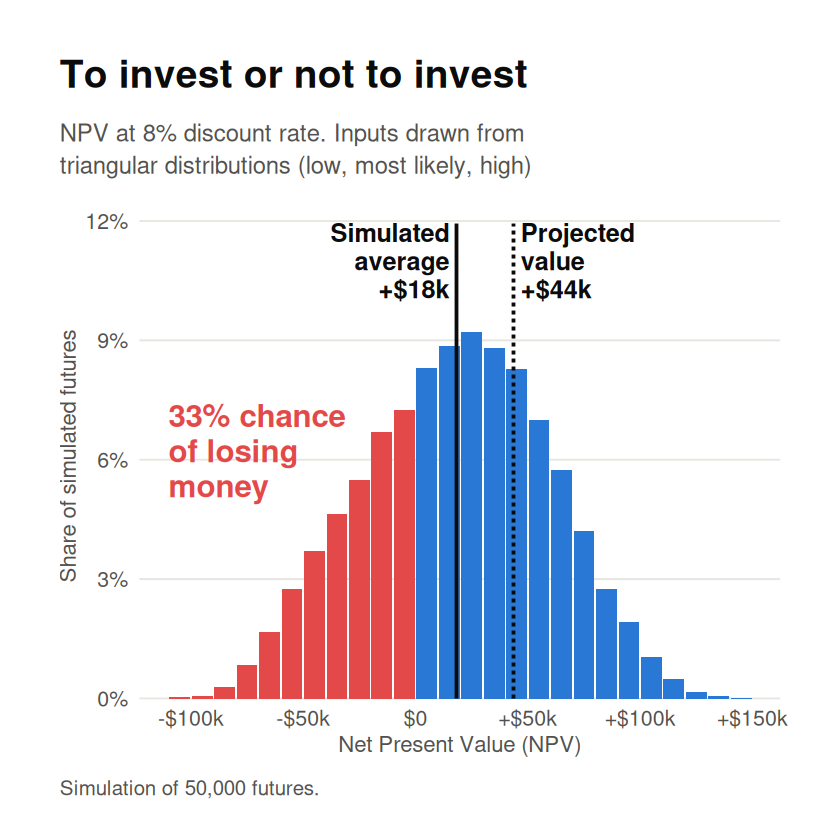

In [5]:
# Chart
blue <- "#2a78d6"   
red <- "#e34948"   
ink <- "#0b0b0b"
ink2 <- "#52514e"

bin <- 10000
df <- data.frame(left = floor(sim/bin)*bin)
bars <- aggregate(list(n = rep(1,n_sims)),by = list(left = df$left), FUN = sum)
bars$share <- bars$n/n_sims*100
bars$loss <- bars$left < 0
gap <- 1200
top <- max(bars$share)

ggplot(bars) +
geom_rect(aes(xmin = left+gap/2,xmax = left+bin-gap/2,
              ymin = 0,ymax = share,fill = loss)) +
scale_fill_manual(values = c(`FALSE` = blue,`TRUE` = red),guide = "none") +
annotate("segment",x = plan_npv,xend = plan_npv,y = 0,yend = top*1.30,
         colour = ink,linewidth = 0.8,linetype = "dashed") +
annotate("text",x = plan_npv+3000,y = top*1.30,hjust = 0,vjust = 1,
         label = sprintf("Projected \nvalue\n%s",fmt(plan_npv)),
         colour = ink,size = 5.2,fontface = "bold",lineheight = 0.95) +
annotate("segment",x = avg_npv,xend = avg_npv,y = 0,yend = top*1.30,
         colour = ink,linewidth = 0.8) +
annotate("text",x = avg_npv- 3000,y = top*1.30,hjust = 1,vjust = 1,
         label = sprintf("Simulated\naverage\n%s",fmt(avg_npv)),
         colour = ink,size = 5.2,fontface = "bold",lineheight = 0.95) +
annotate("text",x = min(bars$left),y = top*0.55,hjust = 0,vjust = 0,
         label = sprintf("%.0f%% chance\nof losing\nmoney",100*p_loss),
         colour = red,size = 6.5,fontface = "bold",lineheight = 0.95) +
scale_x_continuous(labels = function(x) ifelse(x == 0,paste0(currency,0),fmt(x)),
                   breaks = seq(-100000,150000,by = 50000)) +
scale_y_continuous(labels = function(y) paste0(y,"%"),
                   expand = expansion(mult = c(0,0.02))) +
labs(title = "To invest or not to invest",
     subtitle = sprintf("NPV at %.0f%% discount rate. Inputs drawn from \ntriangular distributions (low, most likely, high)",
                        100*discount_rate),
     x = "Net Present Value (NPV)",
     y = "Share of simulated futures",
     caption = sprintf(paste0("Simulation of %s futures."),
                       format(n_sims,big.mark = ","))) +
theme_minimal(base_size = 15) +
theme(plot.background = element_rect(fill = "white",colour = NA),
      plot.title = element_text(face = "bold",size = 23,colour = ink,
                                lineheight = 1.05),
      plot.subtitle = element_text(size = 14,colour = ink2,lineheight = 1.15,
                                   margin = margin(t = 8,b = 20)),
      plot.caption = element_text(size = 12,colour = ink2,hjust = 0,
                                  margin = margin(t = 14)),
      plot.title.position = "plot",
      plot.caption.position = "plot",
      axis.title = element_text(colour = ink2,size = 13),
      axis.text = element_text(colour = ink2,size = 12.5),
      panel.grid.major.x = element_blank(),
      panel.grid.minor = element_blank(),
      panel.grid.major.y = element_line(colour = "#e6e5e0",linewidth = 0.4),
      plot.margin = margin(36,36,24,36))

The chart shows 50,000 simulated outcomes drawn from triangular distributions based on these estimates. Red bars represent losses, while blue bars represent gains.

The results reveal a less attractive picture:<br>
- Average value: +$\$$18,000, less than half the projected figure<br>
- 33% chance of losing money<br>
- Just 28% chance of achieving the projected value<br>

Why? The potential downside outweighs the upside.

Daily sales could fall to 15 cakes, but increase to only 55.
Annual running costs could rise to $\$$28,000, but fall to only $\$$18,000.

This does not necessarily mean the bakery should reject the investment. Instead, the analysis shifts the decision from simply asking whether the oven is profitable to considering more practical questions:<br>
- Can demand be tested before committing? For example, by taking pre-orders for a month.<br>
- Could leasing replace buying and limit the potential loss?<br>
- Is a 1-in-3 chance of losing money acceptable for the business?